<a href="https://colab.research.google.com/github/Kizsi2025/04-neuron-13c-37/blob/main/neuron_halo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Bolyai Labs – Feladatkártya #4: Neuronok a gépben

> Fejlesztőként szeretném a hívásjóslót neurális hálóval is megépíteni (PyTorch), hogy később képekre és szövegre is bővíthessük.

Négy lépésben haladsz:
- **a)** kézi neuron: súlyozott összeg + eltolás + aktiváció;
- **b)** a tanítási ciklus négy sora;
- **c)** XOR: amit egy neuron nem tud, azt két réteg igen;
- **d)** hívásjósló háló a novemberi naplón, összevetve a 3. blokk logisztikus regressziójával (0,828).

Ahol `...  # TODO` áll, oda írd a megoldást. **Mentés:** File → Save a copy in GitHub → saját repó, `main`, fájlnév `neuron_halo.ipynb`, commitüzenet: `feat: első neurális háló (feladatkártya #4)`.

In [1]:
import json
from pathlib import Path

import pandas as pd
import torch
from torch import nn
from sklearn.metrics import accuracy_score, recall_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

torch.manual_seed(0)  # így mindenkinél ugyanazokkal a kezdősúlyokkal indul a háló
ADAT = Path("data/hivasok_november.csv")
df = pd.read_csv(ADAT if ADAT.exists() else "https://raw.githubusercontent.com/Kizsi2025/bolyai-labs-04-neuron/main/data/hivasok_november.csv")
df["modell_nagyobb"] = (df["modell"] == "nagyobb").astype(int)
print("PyTorch verzió:", torch.__version__, "| sorok:", len(df))

PyTorch verzió: 2.14.1+cpu | sorok: 1000


## a) Kézi neuron
Egy neuron: **z = x · w + b**, majd aktiváció: **σ(z) = 1 / (1 + e⁻ᶻ)**.
Írd meg a `neuron` függvényt! (Tipp: `x @ w` a súlyozott összeg, `torch.sigmoid` az aktiváció.)
Számold ki fejben is az órai példát: x = (1; 2), w = (0,5; −0,25), b = 0,1. Mennyi z? Stimmel a gép eredménye?

In [2]:
def neuron(x, w, b):
    return torch.sigmoid(x @ w + b)

x = torch.tensor([1.0, 2.0])
w = torch.tensor([0.5, -0.25])
b = torch.tensor(0.1)
neuron_ertek = float(neuron(x, w, b))
print("A neuron kimenete:", round(neuron_ertek, 4))

A neuron kimenete: 0.525


## b) A tanítási ciklus
Minden epochban négy lépés ismétlődik:
1. `opt.zero_grad()` – töröljük az előző kör gradienseit;
2. `veszteseg = lossfv(modell(X), y)` – előre irány (forward) és a hiba kiszámítása;
3. `veszteseg.backward()` – visszaterjesztés: minden súlyra kiszámoljuk, merre csökken a hiba;
4. `opt.step()` – az optimalizáló lép egy kicsit a súlyokkal.

Írd be a négy sort a ciklusba! A függvény visszaadja a veszteségek listáját, hogy lássuk a tanulási görbét.

In [3]:
def tanit(modell, X, y, epochok=300, lr=0.05):
    opt = torch.optim.Adam(modell.parameters(), lr=lr)
    lossfv = nn.BCEWithLogitsLoss()  # a szigmoidot ez végzi el, ezért a háló végén nincs Sigmoid réteg
    vesztesegek = []
    for epoch in range(epochok):
        opt.zero_grad()
        veszteseg = lossfv(modell(X), y)
        veszteseg.backward()
        opt.step()
        vesztesegek.append(veszteseg.item())
    return vesztesegek

## c) XOR: amit egy neuron nem tud
A XOR akkor 1, ha a két bemenet különbözik. Egyetlen neuron csak egy egyenessel tudja kettéosztani a síkot – ez itt kevés.
Futtasd az egyneuronos változatot, aztán építs egy **kétrétegű hálót**: `Linear(2, 8)` → `ReLU` → `Linear(8, 1)`.

In [5]:
Xx = torch.tensor([[0., 0.], [0., 1.], [1., 0.], [1., 1.]])
yx = torch.tensor([[0.], [1.], [1.], [0.]])

def pontossag(modell, X, y):
    with torch.no_grad():
        return ((modell(X) > 0).float() == y).float().mean().item()

torch.manual_seed(0)
egy_neuron = nn.Linear(2, 1)
tanit(egy_neuron, Xx, yx, epochok=1000)
xor_egy_neuron = pontossag(egy_neuron, Xx, yx)

torch.manual_seed(0)
xor_halo = nn.Sequential(nn.Linear(2, 8), nn.ReLU(), nn.Linear(8, 1))
tanit(xor_halo, Xx, yx, epochok=1000)
xor_halo_pont = pontossag(xor_halo, Xx, yx)
print("Egy neuron:", xor_egy_neuron, "| kétrétegű háló:", xor_halo_pont)

Egy neuron: 0.5 | kétrétegű háló: 1.0


## d) Hívásjósló háló
Ugyanaz a felosztás és standardizálás, mint a 3. blokkban – csak most tenzorokká alakítjuk az adatot.
Építs egy hálót: **3 bemenet → 8 rejtett neuron (ReLU) → 1 kimenet**, és tanítsd 300 epochig.

In [7]:
X = df[["tokenek", "valaszido_ms", "modell_nagyobb"]]
y = df["sikeres"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)
skala = StandardScaler().fit(X_train)
Xt = torch.tensor(skala.transform(X_train), dtype=torch.float32)
Xv = torch.tensor(skala.transform(X_test), dtype=torch.float32)
yt = torch.tensor(y_train.values, dtype=torch.float32).reshape(-1, 1)
print(Xt.shape, yt.shape)

torch.Size([750, 3]) torch.Size([750, 1])


In [8]:
torch.manual_seed(0)
halo = nn.Sequential(nn.Linear(3, 8), nn.ReLU(), nn.Linear(8, 1))
parameterek = sum(p.numel() for p in halo.parameters())
vesztesegek = tanit(halo, Xt, yt, epochok=300)
with torch.no_grad():
    jo = (halo(Xv) > 0).int().numpy().ravel()
accuracy = accuracy_score(y_test, jo)
recall_hiba = recall_score(y_test, jo, pos_label=0)
print("Paraméterek:", parameterek)
print("Veszteség:", round(vesztesegek[0], 3), "→", round(vesztesegek[-1], 3))
print("Pontosság:", round(accuracy, 3), "| a sikertelen hívások felidézése:", round(recall_hiba, 3))

Paraméterek: 41
Veszteség: 0.763 → 0.333
Pontosság: 0.824 | a sikertelen hívások felidézése: 0.611


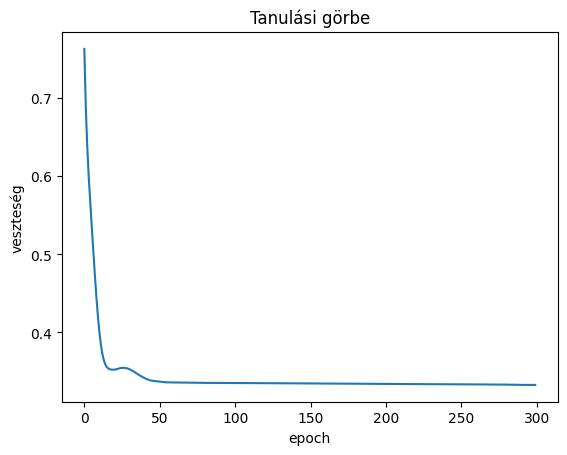

In [9]:
import matplotlib.pyplot as plt
plt.plot(vesztesegek)
plt.xlabel("epoch"); plt.ylabel("veszteség"); plt.title("Tanulási görbe")
plt.show()

## Önellenőrzés és mentés

In [10]:
assert abs(neuron_ertek - 0.525) < 0.001, "a) Nézd át a neuron képletét: sigmoid(x @ w + b)."
assert vesztesegek[-1] < 0.75 * vesztesegek[0], "b) Nem csökken a veszteség – megvan mind a négy sor a ciklusban?"
assert xor_halo_pont == 1.0, "c) A kétrétegű hálónak mind a négy XOR-esetet el kell találnia."
assert parameterek == 41, "d) 3 → 8 → 1 háló kell (41 paraméter)."
assert accuracy >= 0.79, "d) Túl alacsony a pontosság."
Path("eredmenyek").mkdir(exist_ok=True)
json.dump({"neuron_ertek": neuron_ertek, "xor_egy_neuron": xor_egy_neuron, "xor_halo": xor_halo_pont,
           "parameterek": parameterek, "loss_eleje": vesztesegek[0], "loss_vege": vesztesegek[-1],
           "accuracy": accuracy, "recall_hiba": recall_hiba},
          open("eredmenyek/kartya4.json", "w"), indent=1)
print("Minden ellenőrzés rendben!", {"pontosság": round(accuracy, 3), "felidézés": round(recall_hiba, 3)})

Minden ellenőrzés rendben! {'pontosság': 0.824, 'felidézés': 0.611}


## Extra (nem kötelező)
Próbáld ki 16 rejtett neuronnal, vagy `lr=0.005`-tel! Mi változik a tanulási görbén és a pontosságon? (Az extra kísérletet új cellába írd, a fenti cellákat hagyd az eredeti beállításon.)

**Gondolkodj el (a kilépőkérdésekhez):** a háló nagyjából ugyanolyan jó, mint a 3. blokk logisztikus regressziója. Akkor miért érdemes mégis neurális hálót tanulni?